In [2]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.1.1
NumPy version: 2.4.6


In [3]:
# Load Uber dataset
df = pd.read_csv("../data/raw/uber.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [5]:
df.tail()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1
199999,11951496,2010-05-15 04:08:00.00000076,14.1,2010-05-15 04:08:00 UTC,-73.984395,40.720077,-73.985508,40.768793,1


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 23.4 MB


In [7]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


Task : Data Quality Analysis
Before calculating road distances, we need to understand whether our coordinates are reliable.

We'll investigate four things:
1. Missing values.
2. Duplicate records.
3. Invalid latitude and longitude.
4. Geographical outliers.

##  Data Quality Analysis

### 1. Missing Value Analysis

In [8]:
# Check missing values in each column
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [9]:
total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 2


In [10]:
missing_percentage = (total_missing / df.size) * 100

print(f"Missing percentage: {missing_percentage:.4f}%")

Missing percentage: 0.0001%


### 2. Duplicate Record Analysis

In [11]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 0


In [12]:
duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate percentage: 0.00%


In [13]:
coordinate_columns = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude'
]

In [14]:
df[coordinate_columns].describe()

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
count,200000.000000,200000.000000,199999.000000,199999.000000
mean,-72.527638,39.935885,-72.525292,39.923890
std,11.437787,7.720539,13.117408,6.794829
min,-1340.648410,-74.015515,-3356.666300,-881.985513
25%,-73.992065,40.734796,-73.991407,40.733823
50%,-73.981823,40.752592,-73.980093,40.753042
75%,-73.967154,40.767158,-73.963658,40.768001
max,57.418457,1644.421482,1153.572603,872.697628


Remember:
- Latitude must be between -90 and 90.
- Longitude must be between -180 and 180.
Now check invalid coordinates:

In [15]:
invalid_coordinates = (
    ~df['pickup_latitude'].between(-90, 90) |
    ~df['dropoff_latitude'].between(-90, 90) |
    ~df['pickup_longitude'].between(-180, 180) |
    ~df['dropoff_longitude'].between(-180, 180)
)

print("Invalid coordinate records:", invalid_coordinates.sum())

Invalid coordinate records: 13


Check NYC geographical boundaries :

For our NYC project, we'll use an approximate geographical bounding box:

In [16]:
nyc_bounds = (
    df['pickup_latitude'].between(40.30, 41.20) &
    df['dropoff_latitude'].between(40.30, 41.20) &
    df['pickup_longitude'].between(-74.50, -73.40) &
    df['dropoff_longitude'].between(-74.50, -73.40)
)

print("Records inside NYC bounding box:", nyc_bounds.sum())

print("Records outside NYC bounding box:", (~nyc_bounds).sum())

Records inside NYC bounding box: 195699
Records outside NYC bounding box: 4301


### Coordinate Anomaly Investigation

In [17]:
# Check whether all four coordinates are available
complete_coordinates = df[coordinate_columns].notna().all(axis=1)

# Check globally valid coordinate ranges
valid_ranges = (
    df['pickup_latitude'].between(-90, 90) &
    df['dropoff_latitude'].between(-90, 90) &
    df['pickup_longitude'].between(-180, 180) &
    df['dropoff_longitude'].between(-180, 180)
)

# Identify invalid coordinates excluding missing values
invalid_records = complete_coordinates & ~valid_ranges

print("Missing coordinate records:",
      (~complete_coordinates).sum())

print("Invalid coordinate records:",
      invalid_records.sum())

Missing coordinate records: 1
Invalid coordinate records: 12


In [18]:
df.loc[invalid_records, coordinate_columns].head(20)

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
4949,-748.016667,40.739957,-74.003570,40.734192
32549,-74.016055,40.715155,-737.916665,40.697862
48506,-735.200000,40.770092,-73.980187,40.765530
56617,-73.960828,404.433332,-73.988357,40.769037
61793,-73.951385,401.066667,-73.982110,40.754117
75851,-1340.648410,1644.421482,-3356.666300,872.697628
91422,57.418457,1292.016128,1153.572603,-881.985513
103745,-736.216667,40.767035,-73.982377,40.725562
139447,-74.011042,40.709780,-73.983163,493.533332
144253,-768.550000,40.757812,-73.997040,40.740007


In [19]:
pickup_inside_nyc = (
    df['pickup_latitude'].between(40.30, 41.20) &
    df['pickup_longitude'].between(-74.50, -73.40)
)

dropoff_inside_nyc = (
    df['dropoff_latitude'].between(40.30, 41.20) &
    df['dropoff_longitude'].between(-74.50, -73.40)
)

print("Pickup outside NYC:",
      (~pickup_inside_nyc).sum())

print("Dropoff outside NYC:",
      (~dropoff_inside_nyc).sum())

Pickup outside NYC: 4076
Dropoff outside NYC: 4046


In [20]:
outside_nyc = complete_coordinates & (
    ~pickup_inside_nyc | ~dropoff_inside_nyc
)

df.loc[
    outside_nyc,
    coordinate_columns + ['fare_amount']
].head(20)

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,fare_amount
7,0.000000,0.000000,0.000000,0.000000,2.5
11,0.000000,0.000000,0.000000,0.000000,8.5
65,0.000000,0.000000,0.000000,0.000000,6.0
92,0.000000,0.000000,0.000000,0.000000,6.1
120,0.000000,0.000000,0.000000,0.000000,6.5
133,0.000000,0.000000,0.000000,0.000000,6.9
169,0.001782,0.007380,0.000875,0.005670,14.5
237,0.000000,0.000000,0.000000,0.000000,4.1
316,0.000000,0.000000,0.000000,0.000000,17.7
346,0.000000,0.000000,-73.979805,40.786030,15.5


### Zero Coordinate Investigation

In [21]:
# Identify pickup locations at (0, 0)
pickup_zero = (
    (df['pickup_latitude'] == 0) &
    (df['pickup_longitude'] == 0)
)

# Identify dropoff locations at (0, 0)
dropoff_zero = (
    (df['dropoff_latitude'] == 0) &
    (df['dropoff_longitude'] == 0)
)

# Records with either location at (0, 0)
zero_coordinate_records = pickup_zero | dropoff_zero

print("Pickup zero coordinates:", pickup_zero.sum())
print("Dropoff zero coordinates:", dropoff_zero.sum())
print("Records with zero coordinates:",
      zero_coordinate_records.sum())

Pickup zero coordinates: 3779
Dropoff zero coordinates: 3756
Records with zero coordinates: 3948


In [22]:
# Create a separate working DataFrame
df_quality = df.copy()

# Missing coordinates
df_quality['has_missing_coordinates'] = (
    df_quality[coordinate_columns].isna().any(axis=1)
)

# Globally invalid coordinates
df_quality['has_invalid_coordinates'] = (
    ~df_quality['pickup_latitude'].between(-90, 90) |
    ~df_quality['dropoff_latitude'].between(-90, 90) |
    ~df_quality['pickup_longitude'].between(-180, 180) |
    ~df_quality['dropoff_longitude'].between(-180, 180)
)

# Zero coordinates
df_quality['has_zero_coordinates'] = (
    ((df_quality['pickup_latitude'] == 0) &
     (df_quality['pickup_longitude'] == 0)) |
    ((df_quality['dropoff_latitude'] == 0) &
     (df_quality['dropoff_longitude'] == 0))
)

# Check NYC boundaries
df_quality['pickup_in_nyc'] = (
    df_quality['pickup_latitude'].between(40.30, 41.20) &
    df_quality['pickup_longitude'].between(-74.50, -73.40)
)

df_quality['dropoff_in_nyc'] = (
    df_quality['dropoff_latitude'].between(40.30, 41.20) &
    df_quality['dropoff_longitude'].between(-74.50, -73.40)
)

# Eligible for our initial NYC routing experiment
df_quality['eligible_for_routing'] = (
    ~df_quality['has_missing_coordinates'] &
    ~df_quality['has_invalid_coordinates'] &
    ~df_quality['has_zero_coordinates'] &
    df_quality['pickup_in_nyc'] &
    df_quality['dropoff_in_nyc']
)

In [23]:
quality_columns = [
    'has_missing_coordinates',
    'has_invalid_coordinates',
    'has_zero_coordinates',
    'pickup_in_nyc',
    'dropoff_in_nyc',
    'eligible_for_routing'
]

df_quality[quality_columns].sum()

has_missing_coordinates         1
has_invalid_coordinates        13
has_zero_coordinates         3948
pickup_in_nyc              195924
dropoff_in_nyc             195954
eligible_for_routing       195699
dtype: int64

Create the clean NYC dataset:
We will now create a separate DataFrame containing only eligible records. We will not modify or delete anything from the original df.

In [24]:
# Keep only records eligible for road routing
df_nyc = df_quality[
    df_quality['eligible_for_routing']
].copy()

print("Original dataset shape:", df.shape)
print("Clean NYC dataset shape:", df_nyc.shape)

print("\nRemaining ineligible records:",
      len(df_quality) - len(df_nyc))

print("\nMissing values in clean dataset:")
print(df_nyc[coordinate_columns].isna().sum())

Original dataset shape: (200000, 9)
Clean NYC dataset shape: (195699, 15)

Remaining ineligible records: 4301

Missing values in clean dataset:
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
dtype: int64


## Data Cleaning Decisions

### Original Dataset
- Total records: 200,000
- Total columns: 9

### Identified Data Quality Issues
- Missing coordinate records: 1
- Globally invalid coordinate records: 13
- Records containing zero coordinates: 3,948
- Records outside the selected NYC bounding box: 4,301

### Filtering Criteria
A record is eligible for road routing when:
1. All pickup and dropoff coordinates are present.
2. All latitude and longitude values are within valid geographic ranges.
3. Neither pickup nor dropoff coordinates equal (0, 0).
4. Both pickup and dropoff locations are inside the selected NYC bounding box.

### Cleaning Results
- Original records: 200,000
- Eligible records: 195,699
- Excluded records: 4,301

The original dataset remains unchanged.
A separate filtered DataFrame (`df_nyc`) is used for subsequent processing.

Calculate Haversine Distance:
Before introducing OSRM (road routing), we need to calculate the straight-line distance between each taxi pickup and dropoff location.
1. Understand the concept

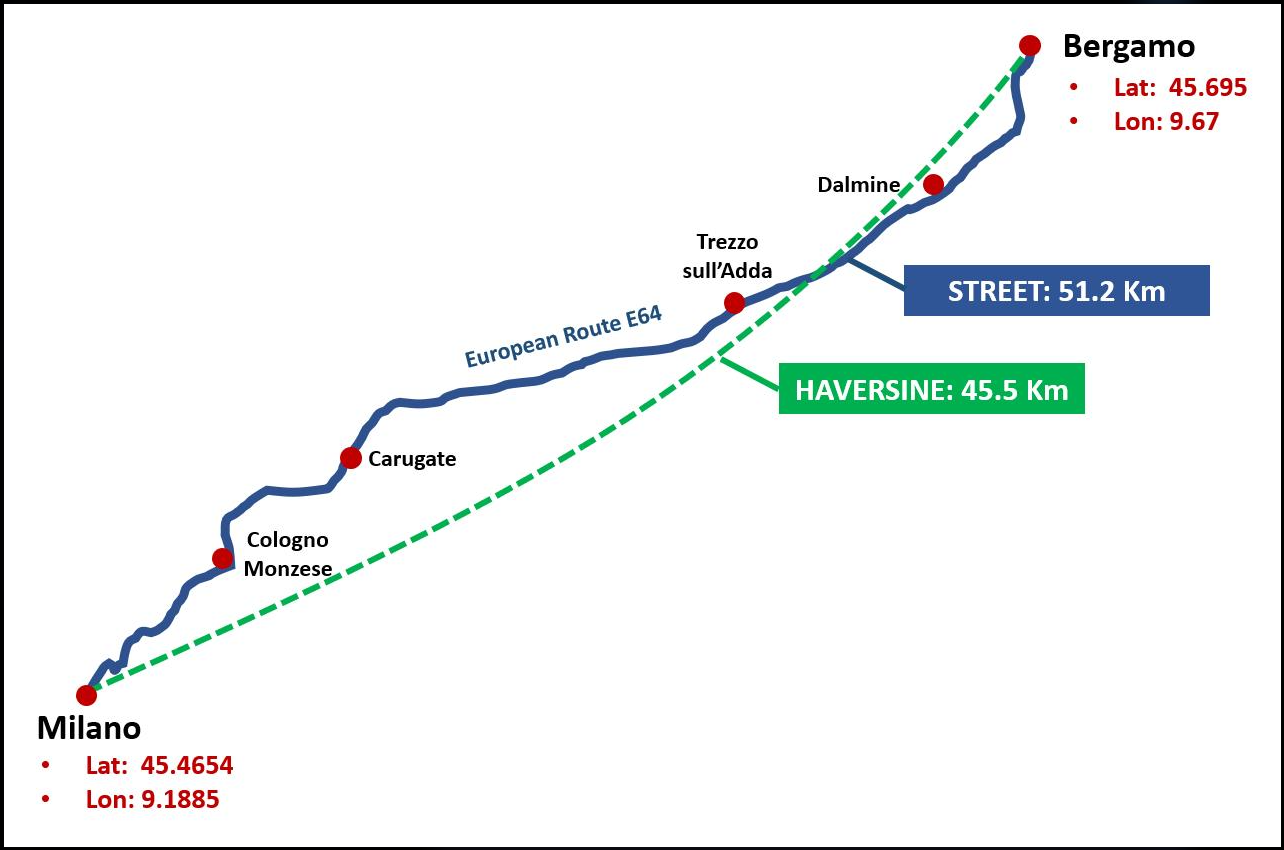

There are two different distances:
- Haversine distance: Straight-line distance between two geographic coordinates, measured along the Earth's surface.
- Road distance: Estimated distance along roads, which we'll calculate later using OSRM.
For example, a taxi trip might have:
- Haversine distance: 5 km
- Road distance: 7.2 km
Road distance is usually longer because roads aren't perfectly straight.

## Haversine Distance Calculation

Haversine distance calculates the great-circle distance between two geographic coordinates on Earth.

It uses:
- Pickup latitude and longitude
- Dropoff latitude and longitude
- Earth's radius

The output represents straight-line distance in kilometres.

In [25]:
import numpy as np

Understand the formula

The Haversine formula is:
\[
a = \sin^2(\Delta\phi/2) +
\cos(\phi_1)\cos(\phi_2)\sin^2(\Delta\lambda/2)
\]

\[
d = 2R\arcsin(\sqrt{a})
\]

Where:
- \(\phi_1,\phi_2\): latitudes in radians
- \(\lambda_1,\lambda_2\): longitudes in radians
- \(R\): Earth's radius (approximately 6371 km)
- \(d\): distance in kilometres

In [26]:
def haversine_distance(lat1 ,lon1 ,lat2 ,lon2):
    R = 6371
    phi1 =np.radians(lat1)
    phi2 =np.radians(lat2)
    delta_phi =np.radians(lat2 -lat1)
    delta_lambda =np.radians(lon2 -lon1)

    # Calculate a
    a = np.sin(delta_phi /2)**2 +  np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda /2) **2

    #Calculate distance d
    d = 2 * R * np.arcsin(np.sqrt(a))

    return d


distance = haversine_distance(40.7580,-73.9855,40.7829,-73.9654)
print(distance)

3.245159886252834


In [27]:
df_nyc['haversine_distance_km'] = haversine_distance(
    df_nyc['pickup_latitude'],
    df_nyc['pickup_longitude'],
    df_nyc['dropoff_latitude'],
    df_nyc['dropoff_longitude']
)

In [28]:
df_nyc[['pickup_latitude',
        'pickup_longitude',
        'dropoff_latitude',
        'dropoff_longitude',
        'haversine_distance_km']].head(10)

,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,haversine_distance_km
0,40.738354,-73.999817,40.723217,-73.999512,1.683323
1,40.728225,-73.994355,40.750325,-73.994710,2.457590
2,40.740770,-74.005043,40.772647,-73.962565,5.036377
3,40.790844,-73.976124,40.803349,-73.965316,1.661683
4,40.744085,-73.925023,40.761247,-73.973082,4.475450
5,40.755910,-73.969019,40.755910,-73.969019,0.000000
6,40.693965,-73.961447,40.774297,-73.871195,11.731015
8,40.745767,-73.975187,40.743537,-74.002720,2.332711
9,40.741787,-74.001065,40.775012,-73.963040,4.889417
10,40.746952,-73.974388,40.729805,-73.988586,2.250858


In [29]:
df_nyc['haversine_distance_km'].describe()

count    195699.000000
mean          3.316987
std           3.596285
min           0.000000
25%           1.256376
50%           2.156609
75%           3.906980
max          60.100889
Name: haversine_distance_km, dtype: float64

In [30]:
# Count zero-distance trips
zero_distance_count = (
    df_nyc['haversine_distance_km'] == 0
).sum()

# Count trips above 30 km
long_trip_count = (
    df_nyc['haversine_distance_km'] > 30
).sum()

# Display the 10 longest trips
longest_trips = df_nyc.nlargest(
    10, 'haversine_distance_km'
)

print("Zero-distance trips:", zero_distance_count)
print("Trips above 30 km:", long_trip_count)

display(
    longest_trips[
        ['pickup_latitude', 'pickup_longitude',
         'dropoff_latitude', 'dropoff_longitude',
         'haversine_distance_km']
    ]
)

Zero-distance trips: 1974
Trips above 30 km: 42


,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,haversine_distance_km
23682,40.644601,-73.782161,40.836457,-74.449079,60.100889
36333,40.685285,-73.806845,41.161225,-73.853342,53.066101
45094,40.643437,-73.789297,40.698832,-74.402822,52.108219
99983,40.749728,-73.971877,41.047272,-73.541785,49.003731
9060,40.640643,-73.788657,41.048048,-74.001350,48.706330
114282,40.644630,-73.781746,40.716450,-74.320007,46.086169
23148,40.644915,-73.781277,41.029780,-73.760570,42.830475
87154,40.773023,-73.960012,41.149037,-74.031707,42.242033
105806,40.725014,-74.011105,40.669371,-73.527638,41.225208
72782,40.772152,-73.876337,41.033868,-73.567932,38.970571


In [31]:
# Select zero-distance trips
zero_distance_trips = df_nyc[
    df_nyc['haversine_distance_km'] == 0
]

print("Zero-distance trip count:",
      len(zero_distance_trips))

print("\nFare amount statistics:")
print(zero_distance_trips['fare_amount'].describe())

print("\nSample zero-distance records:")
display(
    zero_distance_trips[
        ['fare_amount', 'pickup_latitude',
         'pickup_longitude', 'dropoff_latitude',
         'dropoff_longitude']
    ].head(10)
)

Zero-distance trip count: 1974

Fare amount statistics:
count    1974.000000
mean       11.115005
std        14.784627
min         0.000000
25%         4.900000
50%         6.500000
75%        10.100000
max       200.000000
Name: fare_amount, dtype: float64

Sample zero-distance records:


,fare_amount,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude
5,4.90,40.755910,-73.969019,40.755910,-73.969019
48,56.80,40.764686,-73.993498,40.764686,-73.993498
84,49.57,40.788820,-73.975058,40.788820,-73.975058
166,4.50,40.757780,-73.992937,40.757780,-73.992937
361,10.10,40.753475,-73.928705,40.753475,-73.928705
467,4.90,40.760635,-74.002718,40.760635,-74.002718
733,6.90,40.721032,-73.992287,40.721032,-73.992287
1052,6.10,40.761733,-73.970428,40.761733,-73.970428
1306,7.50,40.720980,-73.987150,40.720980,-73.987150
1429,52.00,40.762070,-73.985953,40.762070,-73.985953


In [32]:
# Count zero or negative fares
nonpositive_fares = (
    zero_distance_trips['fare_amount'] <= 0
).sum()

# Count fares above $50
high_fares = (
    zero_distance_trips['fare_amount'] > 50
).sum()

print("Zero/negative fare trips:", nonpositive_fares)
print("Trips with fares above $50:", high_fares)

# Display 10 highest-fare zero-distance trips
display(
    zero_distance_trips.nlargest(
        10, 'fare_amount'
    )[
        ['fare_amount',
         'pickup_latitude',
         'pickup_longitude',
         'dropoff_latitude',
         'dropoff_longitude']
    ]
)

Zero/negative fare trips: 1
Trips with fares above $50: 60


,fare_amount,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude
196647,200.00,40.736298,-73.952994,40.736298,-73.952994
33911,192.33,41.052430,-73.542097,41.052430,-73.542097
79313,130.00,40.734940,-74.369730,40.734940,-74.369730
151599,130.00,40.686410,-73.562940,40.686410,-73.562940
158120,120.00,40.904503,-74.101122,40.904503,-74.101122
131872,110.00,40.510800,-74.242129,40.510800,-74.242129
134524,110.00,40.917693,-74.085449,40.917693,-74.085449
52566,98.00,40.719432,-74.041915,40.719432,-74.041915
44560,96.00,40.695168,-74.177188,40.695168,-74.177188
46345,90.00,40.690009,-74.177891,40.690009,-74.177891


In [33]:
suspicious_fare = zero_distance_trips[
    zero_distance_trips['fare_amount'] <= 0
]

display(suspicious_fare)

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,has_missing_coordinates,has_invalid_coordinates,has_zero_coordinates,pickup_in_nyc,dropoff_in_nyc,eligible_for_routing,haversine_distance_km
20744,25344154,2015-04-22 23:25:07.0000008,0.0,2015-04-22 23:25:07 UTC,-73.658897,40.805199,-73.658897,40.805199,1,False,False,False,True,True,True,0.0


In [34]:
df_nyc['is_zero_distance'] = (
    df_nyc['haversine_distance_km'] == 0
)

df_nyc['has_nonpositive_fare'] = (
    df_nyc['fare_amount'] <= 0
)

print("Zero-distance trips:",
      df_nyc['is_zero_distance'].sum())

print("Nonpositive-fare trips:",
      df_nyc['has_nonpositive_fare'].sum())

print("Both conditions:",
      (
          df_nyc['is_zero_distance'] &
          df_nyc['has_nonpositive_fare']
      ).sum())

Zero-distance trips: 1974
Nonpositive-fare trips: 19
Both conditions: 1


In [35]:
# Select columns needed for the next pipeline stages
final_columns = [
    'key',
    'fare_amount',
    'pickup_datetime',
    'passenger_count',
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'haversine_distance_km',
    'is_zero_distance',
    'has_nonpositive_fare'
]

df_processed = df_nyc[final_columns].copy()

print("Processed dataset shape:", df_processed.shape)

display(df_processed.head())

print("\nMissing values:")
print(df_processed.isna().sum())

Processed dataset shape: (195699, 11)


,key,fare_amount,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,haversine_distance_km,is_zero_distance,has_nonpositive_fare
0,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,1,-73.999817,40.738354,-73.999512,40.723217,1.683323,False,False
1,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,1,-73.994355,40.728225,-73.994710,40.750325,2.457590,False,False
2,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,1,-74.005043,40.740770,-73.962565,40.772647,5.036377,False,False
3,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,3,-73.976124,40.790844,-73.965316,40.803349,1.661683,False,False
4,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,5,-73.925023,40.744085,-73.973082,40.761247,4.475450,False,False



Missing values:
key                      0
fare_amount              0
pickup_datetime          0
passenger_count          0
pickup_longitude         0
pickup_latitude          0
dropoff_longitude        0
dropoff_latitude         0
haversine_distance_km    0
is_zero_distance         0
has_nonpositive_fare     0
dtype: int64


In [36]:
print(df_processed.dtypes)

key                          str
fare_amount              float64
pickup_datetime              str
passenger_count            int64
pickup_longitude         float64
pickup_latitude          float64
dropoff_longitude        float64
dropoff_latitude         float64
haversine_distance_km    float64
is_zero_distance            bool
has_nonpositive_fare        bool
dtype: object


In [37]:
print(df_processed.iloc[0].to_dict())

{'key': '2015-05-07 19:52:06.0000003', 'fare_amount': 7.5, 'pickup_datetime': '2015-05-07 19:52:06 UTC', 'passenger_count': 1, 'pickup_longitude': -73.99981689453125, 'pickup_latitude': 40.73835372924805, 'dropoff_longitude': -73.99951171875, 'dropoff_latitude': 40.72321701049805, 'haversine_distance_km': 1.6833227524029715, 'is_zero_distance': False, 'has_nonpositive_fare': False}


In [38]:
# Convert pickup_datetime into UTC datetime
df_processed['pickup_datetime'] = pd.to_datetime(
    df_processed['pickup_datetime'],
    utc=True
)

# Verify the conversion
print("Data type:",
      df_processed['pickup_datetime'].dtype)

print("\nSample values:")
print(df_processed['pickup_datetime'].head())

print("\nMissing datetime values:",
      df_processed['pickup_datetime'].isna().sum())

Data type: datetime64[us, UTC]

Sample values:
0   2015-05-07 19:52:06+00:00
1   2009-07-17 20:04:56+00:00
2   2009-08-24 21:45:00+00:00
3   2009-06-26 08:22:21+00:00
4   2014-08-28 17:47:00+00:00
Name: pickup_datetime, dtype: datetime64[us, UTC]

Missing datetime values: 0


Why use Parquet instead of CSV:

Feature         	CSV         	Parquet

Storage	            Text	        Binary

Compression	        Limited	        Efficient

Data types	     Often inferred	    Preserved

Column-based queries Less efficient	More efficient

Big Data tools	  Supported	        Widely supported

In [39]:
df_processed.to_parquet(
    "../data/processed/uber_haversine.parquet",
    index=False,
    engine="pyarrow"
)

In [40]:
import os

file_path = "../data/processed/uber_haversine.parquet"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size (MB):",
        round(os.path.getsize(file_path) / (1024 ** 2), 2)
    )

File exists: True
File size (MB): 10.06


In [41]:
df_check = pd.read_parquet(file_path)

print("Original shape:", df_processed.shape)
print("Reloaded shape:", df_check.shape)

print("\nData types:")
print(df_check.dtypes)

Original shape: (195699, 11)
Reloaded shape: (195699, 11)

Data types:
key                                      str
fare_amount                          float64
pickup_datetime          datetime64[us, UTC]
passenger_count                        int64
pickup_longitude                     float64
pickup_latitude                      float64
dropoff_longitude                    float64
dropoff_latitude                     float64
haversine_distance_km                float64
is_zero_distance                        bool
has_nonpositive_fare                    bool
dtype: object


## OSRM Road Distance Calculation :-